# 06 · Trust regions: TRPO and PPO

> **Where we are.** Notebook 04 gave us the policy gradient (REINFORCE), and 05 gave us the critic and GAE that make
> it low-variance. This notebook answers the question that is left: **how big a step may we take?**
> The answer, the *trust region*, gives us TRPO (2015) and its simpler practical successor PPO (2017).
> PPO is the RL algorithm behind InstructGPT and ChatGPT, so this is the bridge to LLM alignment in notebook 07.

```mermaid
flowchart LR
    N04["04 REINFORCE"] --> N05["05 Actor-critic + GAE"]
    N05 --> N06["06 TRPO / PPO<br/>(you are here)"]:::here
    N06 --> N07["07 RLHF with PPO"]
    N06 --> N09["09 GRPO family<br/>(PPO without a critic)"]
    classDef here fill:#dbeafe,stroke:#2563eb,stroke-width:3px
```

**What you will learn**

1. Why plain policy-gradient training *collapses* when you take big steps or reuse data, shown live.
2. **Importance sampling**: how to reuse samples from an *old* policy to evaluate a *new* one, and why it blows up.
3. The **surrogate objective** and the **KL trust region** it needs.
4. **Natural gradient** and the **Fisher information matrix**: measuring step size in "probability space", not parameter space.
5. **TRPO** from scratch: conjugate gradient, Fisher-vector products, and a backtracking line search.
6. **PPO-clip** from scratch: the clipped objective, value loss, entropy bonus, minibatch epochs.
7. How all of this maps to LLM training.

## 0. Setup

We reuse the plotting helpers from `rlkit` (plots and GIFs only). Every RL algorithm in this notebook is written below from scratch.

In [1]:
# Setup: make the shared `rlkit` helpers (plots, GIFs, toy envs, tiny models) importable.
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))
%matplotlib inline

In [2]:
import math, random, time, copy
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from rlkit.viz import COLORS, Animator, setup_style, plot_curves, smooth, save_figure, show_frame

setup_style()
torch.set_num_threads(1)  # tiny networks are faster single-threaded
print("torch", torch.__version__)

torch 2.13.0


## 1. The environment: CartPole in 30 lines of pure Python

A pole is hinged on a cart. Each step the agent pushes the cart **left (0)** or **right (1)**, and gets **+1 reward for every step the pole stays up**.
The episode ends when the pole tilts beyond 12° or the cart leaves the track (|x| > 2.4). We cap episodes at 200 steps, so the best possible return is **200**.

The physics are the classic equations from Barto, Sutton & Anderson (1983), integrated with Euler steps of 20 ms, the same as OpenAI Gym's `CartPole-v0`.

In [3]:
class CartPole:
    """Cart-pole balancing, written from scratch (no gym). State = [x, x_dot, theta, theta_dot]."""

    gravity, masscart, masspole, length, force_mag, tau = 9.8, 1.0, 0.1, 0.5, 10.0, 0.02

    def __init__(self, seed: int = 0, max_steps: int = 200):
        self.rng = random.Random(seed)
        self.max_steps = max_steps
        self.episode_return = 0.0
        self.reset()

    def reset(self):
        self.state = [self.rng.uniform(-0.05, 0.05) for _ in range(4)]
        self.t = 0
        return list(self.state)

    def step(self, action: int):
        x, x_dot, th, th_dot = self.state
        force = self.force_mag if action == 1 else -self.force_mag
        cos, sin = math.cos(th), math.sin(th)
        total_mass = self.masscart + self.masspole
        pole_ml = self.masspole * self.length
        temp = (force + pole_ml * th_dot ** 2 * sin) / total_mass
        th_acc = (self.gravity * sin - cos * temp) / (self.length * (4 / 3 - self.masspole * cos ** 2 / total_mass))
        x_acc = temp - pole_ml * th_acc * cos / total_mass
        # Euler integration
        x, x_dot = x + self.tau * x_dot, x_dot + self.tau * x_acc
        th, th_dot = th + self.tau * th_dot, th_dot + self.tau * th_acc
        self.state = [x, x_dot, th, th_dot]
        self.t += 1
        fell = abs(x) > 2.4 or abs(th) > 12 * math.pi / 180
        truncated = self.t >= self.max_steps
        return list(self.state), 1.0, fell, truncated


env = CartPole(seed=0)
s, steps = env.reset(), 0
while True:
    s, r, fell, trunc = env.step(random.randint(0, 1))
    steps += 1
    if fell or trunc:
        break
print(f"a random policy keeps the pole up for {steps} steps")

a random policy keeps the pole up for 29 steps


### The actor-critic network and the rollout buffer (recap of notebook 05)

* **Actor** $\pi_\theta(a\mid s)$: an MLP that outputs 2 logits → a categorical distribution over {left, right}.
* **Critic** $V_\phi(s)$: an MLP that predicts the expected future return from state $s$.
* **Rollout**: run 8 environments in lock-step for 128 steps (= 1024 transitions), store everything, then compute
  **GAE advantages** $\hat A_t$ (notebook 05):

$$\delta_t = r_t + \gamma V(s_{t+1})(1-d_t) - V(s_t), \qquad \hat A_t = \delta_t + \gamma\lambda(1-d_t)\hat A_{t+1}.$$

We also store the **log-probability of every action under the policy that took it**, $\log\pi_{\theta_\text{old}}(a_t\mid s_t)$.
Every algorithm below needs it.

In [4]:
class ActorCritic(nn.Module):
    """Separate actor and critic MLPs (sharing a trunk makes the two losses fight; separate is simpler)."""

    def __init__(self, obs_dim: int = 4, n_actions: int = 2, hidden: int = 64):
        super().__init__()
        self.pi = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(),
                                nn.Linear(hidden, n_actions))
        self.v = nn.Sequential(nn.Linear(obs_dim, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh(),
                               nn.Linear(hidden, 1))

    def dist(self, obs: torch.Tensor) -> torch.distributions.Categorical:
        return torch.distributions.Categorical(logits=self.pi(obs))

    def value(self, obs: torch.Tensor) -> torch.Tensor:
        return self.v(obs).squeeze(-1)


class Rollout:
    """Collects T steps from N parallel envs and computes GAE advantages + returns."""

    def __init__(self, n_envs: int = 8, T: int = 128, gamma: float = 0.99, lam: float = 0.95, seed: int = 0):
        self.envs = [CartPole(seed=seed * 100 + i) for i in range(n_envs)]
        self.obs = [e.reset() for e in self.envs]
        self.T, self.gamma, self.lam = T, gamma, lam

    def collect(self, model: ActorCritic):
        obs_l, act_l, logp_l, rew_l, done_l, val_l, finished = [], [], [], [], [], [], []
        for _ in range(self.T):
            o = torch.tensor(self.obs, dtype=torch.float32)
            with torch.no_grad():
                d = model.dist(o)
                a = d.sample()
                logp, v = d.log_prob(a), model.value(o)
            rewards, dones = [], []
            for i, e in enumerate(self.envs):
                s, r, fell, trunc = e.step(int(a[i]))
                e.episode_return += r
                if fell or trunc:
                    finished.append(e.episode_return)
                    e.episode_return = 0.0
                    s = e.reset()
                self.obs[i] = s
                rewards.append(r)
                dones.append(float(fell or trunc))
            obs_l.append(o); act_l.append(a); logp_l.append(logp); val_l.append(v)
            rew_l.append(torch.tensor(rewards)); done_l.append(torch.tensor(dones))
        with torch.no_grad():
            last_v = model.value(torch.tensor(self.obs, dtype=torch.float32))
        V, R, D = torch.stack(val_l), torch.stack(rew_l), torch.stack(done_l)
        adv, running = torch.zeros_like(R), torch.zeros(R.shape[1])
        for t in reversed(range(self.T)):                      # GAE backwards in time
            next_v = last_v if t == self.T - 1 else V[t + 1]
            delta = R[t] + self.gamma * next_v * (1 - D[t]) - V[t]
            running = delta + self.gamma * self.lam * (1 - D[t]) * running
            adv[t] = running
        batch = dict(obs=torch.stack(obs_l).flatten(0, 1), act=torch.stack(act_l).flatten(),
                     logp=torch.stack(logp_l).flatten(), adv=adv.flatten(), ret=(adv + V).flatten())
        return batch, finished


def mean_last(xs, k=20):
    xs = xs[-k:]
    return sum(xs) / max(len(xs), 1)

## 2. The problem: big steps and data reuse make policy gradient collapse

Collecting experience is expensive (in LLMs, *generating* text is most of the compute).
So we want to **squeeze many gradient steps out of every batch**. With plain policy gradient that is not safe:

$$\nabla_\theta J \approx \frac{1}{N}\sum_t \nabla_\theta \log \pi_\theta(a_t\mid s_t)\,\hat A_t$$

This estimate is only correct **at the parameters that generated the data**. After a few steps on the same batch, the policy has moved,
the data is "stale", and the gradient keeps pushing the probabilities of "good" actions up **without limit**.
Small changes in parameters can mean huge changes in behaviour: one bad step can make the policy deterministic and wrong.
The new policy then collects terrible data, the next update is worse, and training **collapses**. Unlike supervised learning,
**RL creates its own dataset, so a bad step poisons all future data.**

> **Analogy.** You are walking down a mountain in fog. Your map (the gradient) is only accurate within a few metres of where you
> drew it. Taking a 500 m stride in the map's direction can land you off a cliff. A *trust region* is the leash that says
> "only walk as far as the map is trustworthy".

Let's watch it happen. Below, "naive" = take 10 full-batch gradient epochs on each batch with the importance-weighted objective,
**no clipping, no KL control**, lr = 3e-3.

21.1s  final mean return per seed: [200.0, 100.9, 9.2]


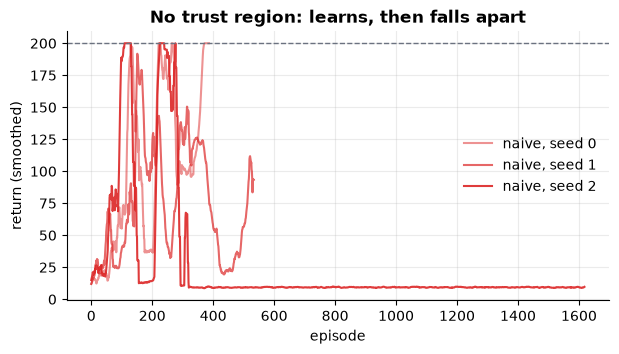

In [5]:
def train_naive(iters=40, seed=0, epochs=10, lr=3e-3):
    """Policy gradient that reuses each batch for many epochs with no trust region."""
    torch.manual_seed(seed)
    model = ActorCritic()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    roll, history = Rollout(seed=seed), []
    for _ in range(iters):
        b, finished = roll.collect(model)
        history += finished
        adv = (b["adv"] - b["adv"].mean()) / (b["adv"].std() + 1e-8)
        for _ in range(epochs):
            d = model.dist(b["obs"])
            ratio = (d.log_prob(b["act"]) - b["logp"]).exp()
            loss = -(ratio * adv).mean() + 0.5 * F.mse_loss(model.value(b["obs"]), b["ret"])
            opt.zero_grad(); loss.backward(); opt.step()
    return history


t0 = time.time()
naive_runs = [train_naive(seed=s) for s in range(3)]
print(f"{time.time() - t0:.1f}s  final mean return per seed:", [round(mean_last(h), 1) for h in naive_runs])
fig, ax = plt.subplots(figsize=(7, 3.5))
for s, h in enumerate(naive_runs):
    ax.plot(smooth(h, 10), color=COLORS["penalty"], alpha=0.5 + 0.2 * s, label=f"naive, seed {s}")
ax.axhline(200, ls="--", color=COLORS["reference"], lw=1)
ax.set(title="No trust region: learns, then falls apart", xlabel="episode", ylabel="return (smoothed)")
ax.legend(); plt.show()

Look at the shape: it often learns fast at first, then **performance suddenly falls off a cliff** and may never recover.
The rest of this notebook is about preventing that cliff.

## 3. Importance sampling: re-using old data correctly

We want the expected advantage under the **new** policy $\pi_\theta$, but our samples came from the **old** policy $\pi_{\theta_\text{old}}$.
Importance sampling (IS) fixes the mismatch by re-weighting each sample:

$$\mathbb{E}_{a\sim \pi_\theta}[f(a)] = \sum_a \pi_\theta(a) f(a) = \sum_a \pi_{\theta_\text{old}}(a)\,\frac{\pi_\theta(a)}{\pi_{\theta_\text{old}}(a)}\,f(a)
= \mathbb{E}_{a\sim \pi_{\theta_\text{old}}}\big[\,r(\theta)\, f(a)\,\big],\qquad r(\theta)=\frac{\pi_\theta(a)}{\pi_{\theta_\text{old}}(a)}.$$

The estimate stays **unbiased**, but its **variance grows quickly as the two distributions drift apart**: a few samples get huge weights.
This is the first reason to keep $\pi_\theta$ close to $\pi_{\theta_\text{old}}$.

**Algorithm steps (importance sampling)**

1. Draw samples $a_i \sim q$ (the old policy). *We can only sample from the distribution we actually ran.*
2. For each sample compute the weight $w_i = p(a_i)/q(a_i)$. *How much more (or less) likely the new policy is to take that action.*
3. Estimate $\mathbb{E}_p[f] \approx \frac1N\sum_i w_i f(a_i)$. *Unbiased for any $p$ that is non-zero only where $q$ is.*
4. Watch the weights: if $\max_i w_i$ is huge, the estimate is dominated by a few samples and is unreliable.

shift 0.0: true   1.00  IS mean   1.00  IS std across trials    0.12
shift 0.5: true   1.75  IS mean   1.74  IS std across trials    0.34
shift 1.0: true   3.00  IS mean   3.01  IS std across trials    1.05
shift 1.5: true   4.75  IS mean   4.83  IS std across trials    3.55
shift 2.0: true   7.00  IS mean   7.36  IS std across trials   11.55
shift 2.5: true   9.75  IS mean  10.77  IS std across trials   32.46


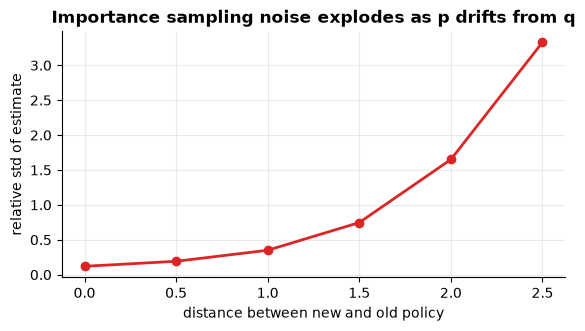

In [6]:
def importance_sampling_demo(shift, n=200, trials=400, seed=0):
    """Estimate E_p[f] for p = N(shift, 1) using samples from q = N(0, 1); f(x) = x^2 + x."""
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(trials, n, generator=g)                     # samples from q
    log_w = (-(x - shift) ** 2 / 2) - (-(x ** 2) / 2)           # log p(x) - log q(x)
    est = (log_w.exp() * (x ** 2 + x)).mean(1)
    true = 1 + shift ** 2 + shift                               # E_p[x^2 + x] in closed form
    return est.mean().item(), est.std().item(), true


shifts = [0.0, 0.5, 1.0, 1.5, 2.0, 2.5]
rows = [importance_sampling_demo(s) for s in shifts]
for s, (m, sd, true) in zip(shifts, rows):
    print(f"shift {s:3.1f}: true {true:6.2f}  IS mean {m:6.2f}  IS std across trials {sd:7.2f}")

fig, ax = plt.subplots(figsize=(6.5, 3.2))
ax.plot(shifts, [r[1] / r[2] for r in rows], "o-", color=COLORS["penalty"], lw=2)
ax.set(title="Importance sampling noise explodes as p drifts from q", xlabel="distance between new and old policy",
       ylabel="relative std of estimate")
save_figure(fig, "06_importance_sampling.png"); plt.show()
assert abs(rows[0][0] - rows[0][2]) < 0.2, "with p == q importance sampling is plain Monte Carlo"
assert rows[-1][1] / rows[-1][2] > 5 * rows[1][1] / rows[1][2], "variance should grow with the shift"

## 4. The surrogate objective and why it needs a trust region

Plug importance sampling into the policy objective (Kakade & Langford 2002, Schulman et al. 2015). The **surrogate objective** is

$$L_{\theta_\text{old}}(\theta) = \mathbb{E}_{s,a\sim\pi_{\theta_\text{old}}}\Big[\,\underbrace{\frac{\pi_\theta(a\mid s)}{\pi_{\theta_\text{old}}(a\mid s)}}_{r_t(\theta)}\,\hat A_t\Big].$$

Two key facts:

1. **At $\theta=\theta_\text{old}$ the gradient of $L$ is exactly the policy gradient**, because
   $\nabla_\theta r_t\big|_{\theta_\text{old}} = \nabla_\theta\pi_\theta/\pi_{\theta_\text{old}} = \nabla_\theta\log\pi_\theta$. We check this numerically below.
2. **Far from $\theta_\text{old}$, $L$ stops tracking the true objective.** It ignores that the *states* visited would change too.
   Schulman et al. (2015) proved a lower bound
   $$J(\theta) \;\ge\; J(\theta_\text{old}) + L_{\theta_\text{old}}(\theta) - C\cdot \max_s \mathrm{KL}\big(\pi_{\theta_\text{old}}(\cdot|s)\,\|\,\pi_\theta(\cdot|s)\big).$$
   So **maximising the surrogate while keeping the KL divergence small is guaranteed to improve the true return.**
   That is the trust region.

In [7]:
# Fact 1, checked numerically: grad of the surrogate at theta_old == the REINFORCE gradient.
torch.manual_seed(0)
probe = ActorCritic()
b, _ = Rollout(seed=0).collect(probe)
params = list(probe.pi.parameters())

d = probe.dist(b["obs"])
pg = torch.autograd.grad((d.log_prob(b["act"]) * b["adv"]).mean(), params)
d = probe.dist(b["obs"])
surr = ((d.log_prob(b["act"]) - b["logp"]).exp() * b["adv"]).mean()
sg = torch.autograd.grad(surr, params)
max_diff = max((x - y).abs().max().item() for x, y in zip(pg, sg))
print("max |grad_surrogate - grad_REINFORCE| =", max_diff)
assert max_diff < 1e-5

max |grad_surrogate - grad_REINFORCE| = 2.2351741790771484e-08


```mermaid
flowchart TD
    A["Collect a batch with pi_old"] --> B["Estimate advantages A_t with GAE"]
    B --> C{"How to step?"}
    C -->|"plain PG: one small step"| D["Wasteful: one gradient step per batch"]
    C -->|"many epochs, no limit"| E["Collapse: ratio r_t explodes"]
    C -->|"TRPO: max L s.t. KL <= delta"| F["Safe step, exact constraint, 2nd-order"]
    C -->|"PPO: clip r_t to 1 +/- eps"| G["Safe-ish step, 1st-order, simple"]
```

## 5. Natural gradient: measure the step in probability space

Ordinary gradient descent takes the steepest step under a **Euclidean** length $\|\Delta\theta\|^2$.
But a parameter step of size 0.1 can barely change one policy and completely flip another; parameter distance is the wrong ruler.
The natural ruler for distributions is the KL divergence. For a small step, a second-order Taylor expansion gives

$$\mathrm{KL}\big(\pi_\theta\,\|\,\pi_{\theta+\Delta}\big) \approx \tfrac12\,\Delta^\top F(\theta)\,\Delta,\qquad
F(\theta) = \mathbb{E}\big[\nabla\log\pi_\theta\,\nabla\log\pi_\theta^\top\big] \;\text{(the Fisher information matrix)}.$$

Maximising the linearised objective $g^\top\Delta$ subject to $\tfrac12\Delta^\top F\Delta \le \delta$ (Lagrangian, set the derivative to 0):

$$\Delta^\star = \sqrt{\frac{2\delta}{g^\top F^{-1} g}}\;F^{-1}g \qquad\text{(natural gradient, Amari 1998; natural policy gradient, Kakade 2001).}$$

**A beautiful special case.** For a softmax policy over $K$ actions with logits $\theta$, $F = \mathrm{diag}(\pi) - \pi\pi^\top$, and
the vanilla gradient of $J=\sum_i\pi_i R_i$ is $g_i = \pi_i(R_i - J)$, i.e. $g = F R$. Therefore $F^{-1}g = R$ (up to a constant shift that does not change the softmax).
**The natural gradient update is just "logit += lr × advantage"**, with no $\pi_i$ factor. Vanilla gradient
multiplies by $\pi_i$, so an action the policy has nearly ruled out gets almost no gradient even when it is the best one. The policy gets **stuck near a corner**.

In [8]:
def softmax_bandit_paths(R, theta0, steps=60, lr=0.5):
    """Vanilla vs natural gradient ascent on J = sum_i pi_i R_i for a 3-armed softmax bandit."""
    R = torch.tensor(R)
    paths = {}
    for kind in ["vanilla", "natural"]:
        th, path = torch.tensor(theta0), []
        for _ in range(steps):
            pi = th.softmax(0)
            path.append(pi.clone())
            J = (pi * R).sum()
            g = pi * (R - J)                          # vanilla gradient wrt logits
            step = g if kind == "vanilla" else (R - J)  # natural gradient F^+ g = R - J (softmax Fisher)
            th = th + lr * step
        paths[kind] = torch.stack(path)
    return paths


R = [1.0, 0.3, 0.0]                  # arm 0 is best
paths = softmax_bandit_paths(R, theta0=[-2.0, 2.0, 0.0])
for k, p in paths.items():
    print(f"{k:8s}: P(best arm) after 10 steps = {p[10, 0]:.3f}, after 60 = {p[-1, 0]:.3f}")
assert paths["natural"][20, 0] > paths["vanilla"][20, 0] + 0.2, "natural gradient escapes the bad corner faster"

vanilla : P(best arm) after 10 steps = 0.016, after 60 = 0.018
natural : P(best arm) after 10 steps = 0.371, after 60 = 1.000


The animation shows the policy as a point moving inside the **probability simplex** (each corner = always pick that arm).
Both start near the corner of the mediocre arm 1. The vanilla gradient crawls because the best arm has a tiny probability.
The natural gradient heads straight for the best arm.


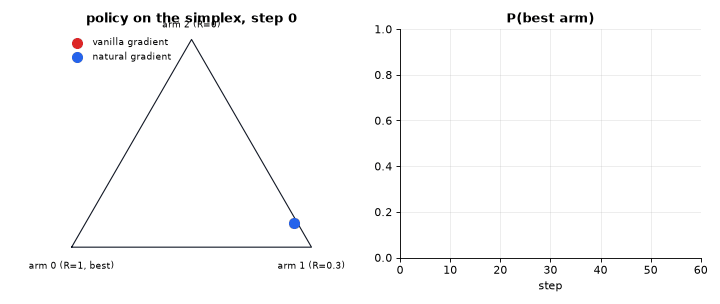

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/06_natural_vs_vanilla.gif')

In [9]:
CORNERS = torch.tensor([[0.0, 0.0], [1.0, 0.0], [0.5, math.sqrt(3) / 2]])


def to_xy(p):  # barycentric coordinates -> 2D
    return p @ CORNERS


def draw_simplex(fig, i):
    fig.clf()
    ax, ax2 = fig.add_subplot(1, 2, 1), fig.add_subplot(1, 2, 2)
    tri = torch.cat([CORNERS, CORNERS[:1]])
    ax.plot(tri[:, 0], tri[:, 1], color=COLORS["ink"], lw=1)
    for c, name in zip(CORNERS, ["arm 0 (R=1, best)", "arm 1 (R=0.3)", "arm 2 (R=0)"]):
        ax.text(c[0], c[1] + (0.05 if c[1] > 0 else -0.09), name, ha="center", fontsize=8)
    for kind, col in [("vanilla", COLORS["penalty"]), ("natural", COLORS["policy"])]:
        xy = to_xy(paths[kind][: i + 1])
        ax.plot(xy[:, 0], xy[:, 1], color=col, lw=2, alpha=0.6)
        ax.scatter(xy[-1, 0], xy[-1, 1], s=80, color=col, zorder=3, label=f"{kind} gradient")
    ax.set_aspect("equal"); ax.axis("off"); ax.legend(loc="upper left", fontsize=8)
    ax.set_title(f"policy on the simplex, step {i}")
    for kind, col in [("vanilla", COLORS["penalty"]), ("natural", COLORS["policy"])]:
        ax2.plot(paths[kind][: i + 1, 0], color=col, lw=2)
    ax2.set(xlim=(0, len(paths["vanilla"])), ylim=(0, 1), title="P(best arm)", xlabel="step")
    fig.tight_layout()


Animator(draw_simplex, n_frames=len(paths["vanilla"]), figsize=(9, 3.8), fps=8).save("06_natural_vs_vanilla.gif")

## 6. TRPO: trust-region policy optimisation (Schulman et al., 2015)

TRPO solves the constrained problem *directly* at every update:

$$\max_\theta\; L_{\theta_\text{old}}(\theta)\quad\text{s.t.}\quad \bar{\mathrm{KL}}(\theta_\text{old},\theta) = \mathbb{E}_s\big[\mathrm{KL}(\pi_{\theta_\text{old}}(\cdot|s)\,\|\,\pi_\theta(\cdot|s))\big] \le \delta.$$

A neural network has thousands of parameters, so we can never build or invert $F$ (a 4 610 × 4 610 matrix even for our tiny actor).
TRPO's trick is to solve $F x = g$ with **conjugate gradient (CG)**, which only needs **Fisher-vector products** $Fv$.
Those come from double back-propagation through the KL: $Fv = \nabla_\theta\big((\nabla_\theta \bar{\mathrm{KL}})^\top v\big)$, because the Hessian of the KL at $\theta_\text{old}$ *is* the Fisher matrix.

**Algorithm steps (TRPO, one update)**

1. **Roll out** the current policy, compute GAE advantages $\hat A_t$ and normalise them. *Same as every actor-critic method.*
2. **Gradient** $g = \nabla_\theta L(\theta)\big|_{\theta_\text{old}}$. *This is just the policy gradient (section 4).*
3. **Solve $Fx = g$ with ~10 CG iterations**, using Fisher-vector products from double backprop. *This gives the natural direction $x\approx F^{-1}g$ without ever forming $F$.*
4. **Scale the step** to the edge of the trust region: $\Delta = \sqrt{2\delta / (x^\top F x)}\,x$. *From $\tfrac12\Delta^\top F\Delta=\delta$.*
5. **Backtracking line search**: try $\theta_\text{old} + \alpha^k\Delta$ for $k=0,1,2,\dots$ ($\alpha=0.5$) and accept the first one where the surrogate improves **and** the *exact* KL $\le\delta$ (with some slack). *The quadratic approximation can be wrong, so verify.*
6. **Fit the critic** $V_\phi$ to the returns with a few Adam steps (critic is not constrained).

### 6a. Conjugate gradient as its own snippet

CG solves $Ax=b$ for a symmetric positive-definite $A$ using only products $Av$. In exact arithmetic it converges in at most $n$ iterations.
In practice ~10 iterations give a good-enough direction.

In [10]:
def conjugate_gradient(Avp, b, iters=10, tol=1e-10):
    """Solve A x = b given only the function v -> A v (A symmetric positive definite)."""
    x = torch.zeros_like(b)
    r = b.clone()          # residual b - A x (x = 0)
    p = b.clone()          # search direction
    rr = r @ r
    for _ in range(iters):
        Ap = Avp(p)
        alpha = rr / (p @ Ap)            # exact line search along p
        x += alpha * p
        r -= alpha * Ap
        rr_new = r @ r
        if rr_new < tol:
            break
        p = r + (rr_new / rr) * p        # next direction, A-conjugate to all previous ones
        rr = rr_new
    return x


# test on a random SPD matrix
torch.manual_seed(0)
M = torch.randn(20, 20)
A = M @ M.T + 20 * torch.eye(20)
b_vec = torch.randn(20)
x = conjugate_gradient(lambda v: A @ v, b_vec, iters=20)
print("CG residual:", (A @ x - b_vec).norm().item())
assert torch.allclose(A @ x, b_vec, atol=1e-3)

CG residual: 8.323672773258295e-06


### 6b. Fisher-vector product + the full TRPO update

In [11]:
from torch.nn.utils import parameters_to_vector, vector_to_parameters


def flat_grad(y, params, **kw):
    return torch.cat([g.reshape(-1) for g in torch.autograd.grad(y, params, **kw)])


def trpo_update(model, b, max_kl=0.01, damping=0.1, cg_iters=10, backtracks=10):
    """One TRPO policy step on batch b (dict from Rollout.collect). Returns (accepted step fraction, KL)."""
    params = list(model.pi.parameters())
    adv = (b["adv"] - b["adv"].mean()) / (b["adv"].std() + 1e-8)
    with torch.no_grad():
        old_dist = torch.distributions.Categorical(logits=model.pi(b["obs"]))

    def surrogate():
        return ((model.dist(b["obs"]).log_prob(b["act"]) - b["logp"]).exp() * adv).mean()

    def mean_kl():
        return torch.distributions.kl_divergence(old_dist, model.dist(b["obs"])).mean()

    def fisher_vector_product(v):
        grad_kl = flat_grad(mean_kl(), params, create_graph=True)      # d KL / d theta (zero at theta_old)
        return flat_grad(grad_kl @ v, params) + damping * v            # Hessian-vector product + damping

    g = flat_grad(surrogate(), params)                                  # step 2
    x = conjugate_gradient(fisher_vector_product, g, iters=cg_iters)   # step 3: x ~ F^-1 g
    step = x * torch.sqrt(2 * max_kl / (x @ fisher_vector_product(x)))  # step 4: edge of trust region
    theta_old = parameters_to_vector(params).detach().clone()
    with torch.no_grad():
        surr_old = surrogate().item()
        for k in range(backtracks):                                     # step 5: backtracking line search
            frac = 0.5 ** k
            vector_to_parameters(theta_old + frac * step, params)
            kl = mean_kl().item()
            if kl <= 1.5 * max_kl and surrogate().item() > surr_old:
                return frac, kl
        vector_to_parameters(theta_old, params)                         # no acceptable step: stay put
    return 0.0, 0.0


def train_trpo(iters=40, seed=0, max_kl=0.01):
    torch.manual_seed(seed)
    model = ActorCritic()
    v_opt = torch.optim.Adam(model.v.parameters(), lr=1e-3)
    roll, history, kls = Rollout(seed=seed), [], []
    for _ in range(iters):
        b, finished = roll.collect(model)
        history += finished
        _, kl = trpo_update(model, b, max_kl=max_kl)
        kls.append(kl)
        for _ in range(20):                                             # step 6: fit the critic
            v_loss = F.mse_loss(model.value(b["obs"]), b["ret"])
            v_opt.zero_grad(); v_loss.backward(); v_opt.step()
    return history, kls


t0 = time.time()
trpo_runs = [train_trpo(seed=s) for s in range(3)]
print(f"{time.time() - t0:.1f}s  final mean return per seed:", [round(mean_last(h), 1) for h, _ in trpo_runs])
print("KL of accepted steps (seed 0, first 10):", [round(k, 4) for k in trpo_runs[0][1][:10]])
assert all(k <= 0.015 + 1e-9 for _, ks in trpo_runs for k in ks), "TRPO must respect the trust region"

32.7s  final mean return per seed: [195.5, 200.0, 199.0]
KL of accepted steps (seed 0, first 10): [0.0089, 0.0085, 0.0087, 0.0082, 0.0085, 0.0061, 0.0091, 0.0036, 0.0048, 0.0064]


Every accepted step has KL ≤ 1.5 δ: **TRPO enforces the trust region exactly**, by construction.
The price is complexity: CG, double backprop, a line search, and an extra forward pass per backtrack. That is painful
for a 7-billion-parameter LLM with dropout, mixed precision and sharded weights. This is what motivated PPO.

## 7. PPO: proximal policy optimisation (Schulman et al., 2017)

PPO keeps TRPO's idea, *don't let the new policy move too far from the old one*, but enforces it with a cheap,
first-order trick inside the loss: **clip the probability ratio**.

$$L^{\text{CLIP}}(\theta) = \mathbb{E}_t\Big[\min\big(r_t(\theta)\hat A_t,\;\mathrm{clip}(r_t(\theta), 1-\epsilon, 1+\epsilon)\,\hat A_t\big)\Big],\qquad \epsilon\approx 0.2.$$

Read it case by case:

* **$\hat A_t > 0$ (good action):** we want to raise $r_t$, but once $r_t > 1+\epsilon$ the clipped term is constant, so **the gradient is zero**.
  There is no incentive to push the probability further in this update.
* **$\hat A_t < 0$ (bad action):** we want to lower $r_t$, but once $r_t < 1-\epsilon$ the gradient is again zero.
* The `min` makes it a **pessimistic lower bound**. If an update has *accidentally* moved $r_t$ the wrong way (e.g. $r_t$ grew although $\hat A_t<0$), the unclipped
  term is the smaller one and the gradient is **not** clipped, so the mistake can be undone.

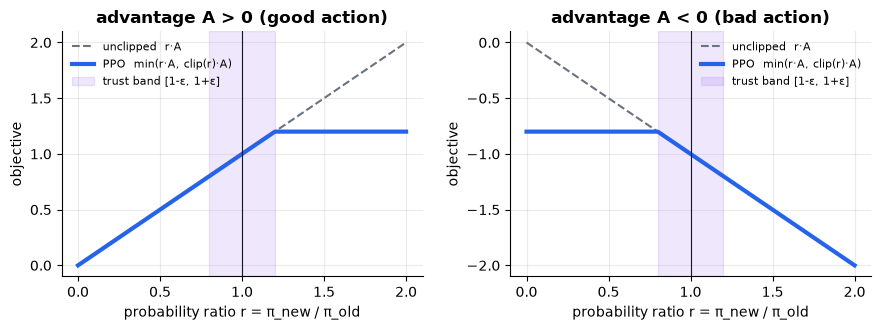

In [12]:
r = torch.linspace(0.0, 2.0, 400)
eps = 0.2
fig, axes = plt.subplots(1, 2, figsize=(9, 3.4), sharey=False)
for ax, A, title in [(axes[0], 1.0, "advantage A > 0 (good action)"), (axes[1], -1.0, "advantage A < 0 (bad action)")]:
    unclipped = r * A
    clipped = torch.minimum(r * A, r.clamp(1 - eps, 1 + eps) * A)
    ax.plot(r, unclipped, "--", color=COLORS["reference"], label="unclipped  r·A")
    ax.plot(r, clipped, color=COLORS["policy"], lw=3, label="PPO  min(r·A, clip(r)·A)")
    ax.axvspan(1 - eps, 1 + eps, color=COLORS["accent"], alpha=0.12, label="trust band [1-ε, 1+ε]")
    ax.axvline(1, color=COLORS["ink"], lw=0.8)
    ax.set(title=title, xlabel="probability ratio r = π_new / π_old", ylabel="objective")
    ax.legend(fontsize=8)
fig.tight_layout()
save_figure(fig, "06_ppo_clip_objective.png"); plt.show()

Flat segments mean **zero gradient**: past the band edge in the "helpful" direction, the sample stops contributing.

### 7a. The PPO loss as a separate snippet

The full PPO loss used in practice has three parts:

$$\mathcal{L}(\theta,\phi) = \underbrace{-L^{\text{CLIP}}(\theta)}_{\text{policy}} \;+\; c_v\,\underbrace{\mathbb{E}_t\big[(V_\phi(s_t)-\hat R_t)^2\big]}_{\text{value regression}} \;-\; c_e\,\underbrace{\mathbb{E}_t\big[\mathcal{H}(\pi_\theta(\cdot|s_t))\big]}_{\text{entropy bonus (keeps exploring)}}$$

In [13]:
def ppo_loss(model, obs, act, old_logp, adv, ret, clip_eps=0.2, c_v=0.5, c_e=0.01):
    """Clipped PPO objective + value loss - entropy bonus. Returns (loss, diagnostics)."""
    dist = model.dist(obs)
    logp = dist.log_prob(act)
    ratio = (logp - old_logp).exp()                          # r_t(theta)
    unclipped = ratio * adv
    clipped = ratio.clamp(1 - clip_eps, 1 + clip_eps) * adv
    policy_loss = -torch.min(unclipped, clipped).mean()      # pessimistic bound, negated for descent
    value_loss = F.mse_loss(model.value(obs), ret)
    entropy = dist.entropy().mean()
    loss = policy_loss + c_v * value_loss - c_e * entropy
    with torch.no_grad():
        approx_kl = ((ratio - 1) - (logp - old_logp)).mean()   # k3 estimator of KL(old || new), see notebook 13
        clip_frac = ((ratio - 1).abs() > clip_eps).float().mean()
    return loss, dict(policy=policy_loss.item(), value=value_loss.item(), entropy=entropy.item(),
                      kl=approx_kl.item(), clip_frac=clip_frac.item())


# Sanity check: at theta == theta_old, ratio == 1 and nothing is clipped.
_, diag = ppo_loss(probe, b["obs"], b["act"], b["logp"], b["adv"], b["ret"])
print(diag)
assert diag["clip_frac"] == 0.0 and abs(diag["kl"]) < 1e-6

{'policy': -7.339611053466797, 'value': 67.22773742675781, 'entropy': 0.6886909008026123, 'kl': -1.1699739843606949e-08, 'clip_frac': 0.0}


### 7b. The full PPO algorithm

**Algorithm steps (PPO-clip with GAE, "PPO2")**

1. **Roll out** $N$ envs × $T$ steps with the current policy, storing $s_t, a_t, r_t, d_t, \log\pi_{\theta_\text{old}}(a_t|s_t), V(s_t)$. *These old log-probs are frozen: they define the trust region.*
2. **Compute GAE advantages and returns** $\hat R_t = \hat A_t + V(s_t)$. *Value targets for the critic.*
3. **For K epochs** (here 4): shuffle the batch and split it into **minibatches** (here 256). *Data reuse is the whole point: 4 epochs × 4 minibatches = 16 gradient steps per rollout.*
4. **Normalise advantages per minibatch** (zero mean, unit std). *Keeps the step size independent of the reward scale.*
5. **Minimise the PPO loss** (clip + value + entropy) with Adam, **clipping the global gradient norm** to 0.5. *A second safety belt.*
6. (Optional) **Early-stop the epochs** if the approximate KL exceeds a target. *Many implementations do this. It is a soft TRPO-style constraint.*
7. Repeat from 1 with the updated policy.

```mermaid
flowchart LR
    R["Rollout: N envs x T steps<br/>store logp_old, V"] --> G["GAE: A_t, R_t"]
    G --> E{"epoch k < K ?"}
    E -->|yes| M["shuffle into minibatches"]
    M --> L["loss = -clip_obj + c_v * value_loss - c_e * entropy"]
    L --> U["Adam step<br/>grad-norm clip"]
    U --> E
    E -->|"no (or KL > target)"| R
```

In [14]:
def train_ppo(iters=40, seed=0, epochs=4, minibatch=256, lr=9e-4, clip_eps=0.2, record_ratios_at=None):
    torch.manual_seed(seed)
    model = ActorCritic()
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    roll, history, diags, snapshot = Rollout(seed=seed), [], [], None
    for it in range(iters):
        b, finished = roll.collect(model)
        history += finished
        if record_ratios_at == it:                     # keep a copy for the ratio animation (section 8)
            snapshot = (copy.deepcopy(model), {k: v.clone() for k, v in b.items()})
        n = b["obs"].shape[0]
        for _ in range(epochs):
            for idx in torch.randperm(n).split(minibatch):
                adv = b["adv"][idx]
                adv = (adv - adv.mean()) / (adv.std() + 1e-8)
                loss, d = ppo_loss(model, b["obs"][idx], b["act"][idx], b["logp"][idx], adv, b["ret"][idx],
                                   clip_eps=clip_eps)
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(model.parameters(), 0.5)
                opt.step()
        diags.append(d)
    return history, diags, model, snapshot


t0 = time.time()
ppo_runs = [train_ppo(seed=s, record_ratios_at=10 if s == 0 else None) for s in range(3)]
print(f"{time.time() - t0:.1f}s  final mean return per seed:", [round(mean_last(h), 1) for h, *_ in ppo_runs])

18.2s  final mean return per seed: [178.8, 152.7, 170.7]


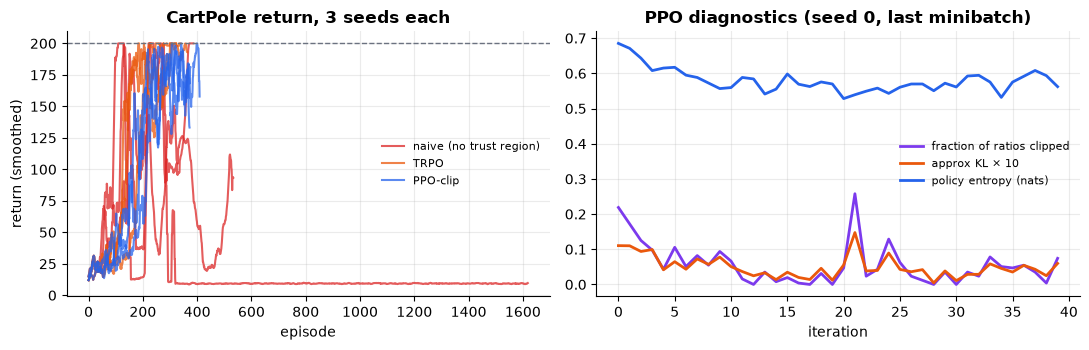

{'naive': 103.4, 'trpo': 198.2, 'ppo': 167.4}


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, runs, col in [("naive (no trust region)", naive_runs, COLORS["penalty"]),
                        ("TRPO", [h for h, _ in trpo_runs], COLORS["value"]),
                        ("PPO-clip", [h for h, *_ in ppo_runs], COLORS["policy"])]:
    for s, h in enumerate(runs):
        axes[0].plot(smooth(h, 10), color=col, alpha=0.75, lw=1.5, label=name if s == 0 else None)
axes[0].axhline(200, ls="--", color=COLORS["reference"], lw=1)
axes[0].set(title="CartPole return, 3 seeds each", xlabel="episode", ylabel="return (smoothed)")
axes[0].legend(fontsize=8)
d0 = ppo_runs[0][1]
axes[1].plot([d["clip_frac"] for d in d0], color=COLORS["accent"], lw=2, label="fraction of ratios clipped")
axes[1].plot([d["kl"] * 10 for d in d0], color=COLORS["value"], lw=2, label="approx KL × 10")
axes[1].plot([d["entropy"] for d in d0], color=COLORS["policy"], lw=2, label="policy entropy (nats)")
axes[1].set(title="PPO diagnostics (seed 0, last minibatch)", xlabel="iteration"); axes[1].legend(fontsize=8)
fig.tight_layout(); save_figure(fig, "06_method_comparison.png"); plt.show()

final = {name: sum(mean_last(h) for h in runs) / 3 for name, runs in
         [("naive", naive_runs), ("trpo", [h for h, _ in trpo_runs]), ("ppo", [h for h, *_ in ppo_runs])]}
print({k: round(v, 1) for k, v in final.items()})
assert final["ppo"] > 150, "PPO should (nearly) solve CartPole-200"
assert final["trpo"] > 100, "TRPO should learn to balance"
assert final["ppo"] > final["naive"], "the trust region should beat unconstrained data reuse"

These numbers are measured on this toy with 3 seeds. On CartPole all three can reach 200 at some point; the difference is
**stability**. The trust-region methods *stay* good, while naive data reuse tends to fall off the cliff.

## 8. Inside one update: watching the ratio distribution

To *see* what clipping does, take one batch from the middle of PPO training and run 10 epochs of updates from the same starting weights.
We do it twice: once with the PPO-clip loss, once with the **unclipped** surrogate. After each epoch we plot the histogram of
$r_t=\pi_\theta/\pi_{\theta_\text{old}}$ over the batch. Green bars are samples with $\hat A>0$ (we want $r>1$); red bars have $\hat A<0$ (we want $r<1$).

PPO-clip            : after 10 epochs, 5% of ratios are outside [0.8, 1.2]; max ratio 1.33
unclipped surrogate : after 10 epochs, 68% of ratios are outside [0.8, 1.2]; max ratio 5.09



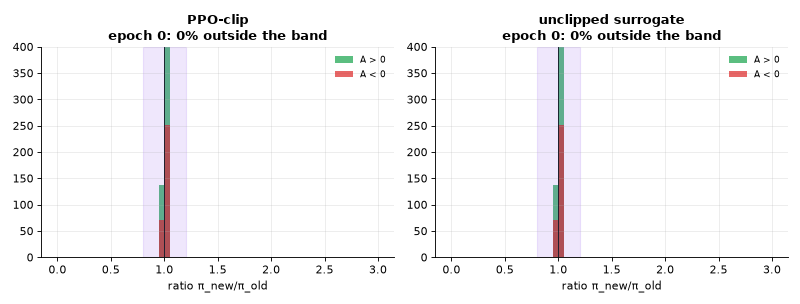

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/06_ratio_histograms.gif')

In [16]:
snap_model, snap_batch = ppo_runs[0][3]
adv_all = (snap_batch["adv"] - snap_batch["adv"].mean()) / (snap_batch["adv"].std() + 1e-8)


def ratios_over_epochs(clip: bool, epochs=10, lr=3e-3):
    model = copy.deepcopy(snap_model)
    opt = torch.optim.Adam(model.pi.parameters(), lr=lr)
    out = []
    for _ in range(epochs + 1):
        with torch.no_grad():
            ratio = (model.dist(snap_batch["obs"]).log_prob(snap_batch["act"]) - snap_batch["logp"]).exp()
        out.append(ratio.clone())
        ratio = (model.dist(snap_batch["obs"]).log_prob(snap_batch["act"]) - snap_batch["logp"]).exp()
        obj = torch.min(ratio * adv_all, ratio.clamp(0.8, 1.2) * adv_all) if clip else ratio * adv_all
        opt.zero_grad(); (-obj.mean()).backward(); opt.step()
    return out


ratio_hist = {"PPO-clip": ratios_over_epochs(True), "unclipped surrogate": ratios_over_epochs(False)}
for k, rs in ratio_hist.items():
    outside = ((rs[-1] - 1).abs() > 0.2).float().mean().item()
    print(f"{k:20s}: after 10 epochs, {outside:.0%} of ratios are outside [0.8, 1.2]; max ratio {rs[-1].max():.2f}")
assert ((ratio_hist["PPO-clip"][-1] - 1).abs() > 0.2).float().mean() < \
       ((ratio_hist["unclipped surrogate"][-1] - 1).abs() > 0.2).float().mean()

BINS = torch.linspace(0, 3, 61)
pos = adv_all > 0


def draw_ratios(fig, i):
    fig.clf()
    for j, (name, rs) in enumerate(ratio_hist.items()):
        ax = fig.add_subplot(1, 2, j + 1)
        r_ = rs[i].clamp(0, 2.99)
        ax.hist(r_[pos].numpy(), bins=BINS.numpy(), color=COLORS["reward"], alpha=0.7, label="A > 0")
        ax.hist(r_[~pos].numpy(), bins=BINS.numpy(), color=COLORS["penalty"], alpha=0.7, label="A < 0")
        ax.axvspan(0.8, 1.2, color=COLORS["accent"], alpha=0.12)
        ax.axvline(1, color=COLORS["ink"], lw=0.8)
        out = ((rs[i] - 1).abs() > 0.2).float().mean().item()
        ax.set(title=f"{name}\nepoch {i}: {out:.0%} outside the band", xlabel="ratio π_new/π_old", ylim=(0, 400))
        ax.legend(fontsize=8, loc="upper right")
    fig.tight_layout()


Animator(draw_ratios, n_frames=11, figsize=(10, 3.8), fps=2).save("06_ratio_histograms.gif")

With clipping, most mass stays inside the purple band. Samples stop being pushed once they leave it, so the new policy remains
"proximal". Without clipping the ratios keep spreading epoch after epoch. That spread is exactly the drift that caused the collapse in section 2.

## 9. What the trained policy does

Finally, the payoff: the cart-pole under a random policy (left) vs the trained PPO policy (right), on the same initial state.

{'random policy': 10, 'PPO policy': 200}



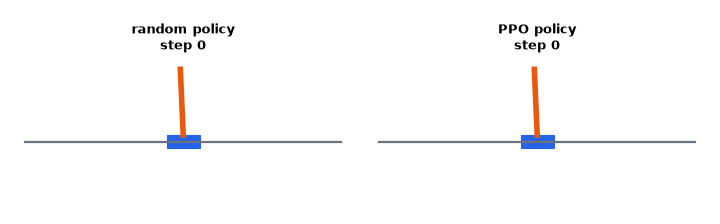

PosixPath('/Users/naveenkumarbasaanitha/Music/HaloDiffusionLLM/assets/rl/course/06_cartpole_random_vs_ppo.gif')

In [17]:
def record_episode(policy_fn, seed=7, max_steps=200):
    env = CartPole(seed=seed, max_steps=max_steps)
    s, states = env.reset(), []
    for _ in range(max_steps):
        states.append(s)
        s, _, fell, trunc = env.step(policy_fn(s))
        if fell or trunc:
            break
    return states


ppo_model = ppo_runs[0][2]
greedy = lambda s: int(ppo_model.pi(torch.tensor(s)).argmax())
rand_rng = random.Random(0)
episodes = {"random policy": record_episode(lambda s: rand_rng.randint(0, 1)), "PPO policy": record_episode(greedy)}
print({k: len(v) for k, v in episodes.items()})
assert len(episodes["PPO policy"]) >= 150


def draw_cartpole(fig, i):
    fig.clf()
    t = min(i * 4, 199)
    for j, (name, states) in enumerate(episodes.items()):
        ax = fig.add_subplot(1, 2, j + 1)
        alive = t < len(states)
        x, _, th, _ = states[min(t, len(states) - 1)]
        col = COLORS["policy"] if alive else COLORS["penalty"]
        ax.plot([-2.4, 2.4], [0, 0], color=COLORS["reference"], lw=2)
        ax.add_patch(plt.Rectangle((x - 0.25, -0.1), 0.5, 0.2, color=col))
        ax.plot([x, x + 1.0 * math.sin(th)], [0.1, 0.1 + 1.0 * math.cos(th)], color=COLORS["value"], lw=5)
        ax.set(xlim=(-2.6, 2.6), ylim=(-0.4, 1.3), title=f"{name}\nstep {min(t, len(states))}" + ("" if alive else "  (fell)"))
        ax.set_aspect("equal"); ax.axis("off")
    fig.tight_layout()


Animator(draw_cartpole, n_frames=50, figsize=(9, 2.8), fps=10).save("06_cartpole_random_vs_ppo.gif")

## 10. Common pitfalls

| Symptom | Likely cause | Fix |
|---|---|---|
| Return rises then crashes | steps too big / too many epochs | lower lr, fewer epochs, KL early-stopping, smaller ε |
| `clip_frac` > 0.3 constantly | policy moves too far per update | lower lr or epochs |
| `clip_frac` ≈ 0 and slow learning | steps far too small | raise lr / epochs |
| Entropy collapses to 0 early | premature determinism | entropy bonus, lower lr |
| Value loss dominates / NaNs | unscaled returns | normalise advantages (and rewards), clip grad norm |
| TRPO step always rejected | bad Fisher estimate | add damping, check KL direction `KL(old ‖ new)` |
| Old log-probs computed with dropout on | ratio ≠ 1 at the start | evaluate deterministically (dropout off), as `rlkit.TinyGPT` does |

Implementation details matter a lot for PPO (Engstrom et al., 2020; Huang et al., 2022, *"The 37 implementation details of PPO"*).

## 11. How this connects to LLM and VLM training

```mermaid
flowchart LR
    subgraph Classic["CartPole PPO"]
      S1["state s_t = cart + pole"] --> A1["action = left/right"]
      A1 --> R1["reward every step"]
    end
    subgraph LLM["LLM PPO (notebook 07)"]
      S2["state = prompt + tokens so far"] --> A2["action = next token"]
      A2 --> R2["reward model score at end<br/>+ per-token KL penalty"]
    end
    Classic -. "same loss, same clip, same GAE" .-> LLM
```

* **The ratio is per token.** For a language model, $r_t = \pi_\theta(y_t\mid x, y_{<t}) / \pi_{\theta_\text{old}}(y_t\mid x, y_{<t})$, computed from one
  teacher-forced forward pass over the sampled response (`rlkit.toy_lm.sequence_logprobs`).
* **Why PPO and not TRPO for LLMs:** PPO needs only first-order gradients and the usual optimiser, so it works with sharded models, mixed precision and LoRA. TRPO's CG + line search does not scale.
* **Typical LLM PPO settings:** ε = 0.2, 1–4 epochs over each batch of generations, small lr (~1e-6 for 7B models), KL-to-reference penalty (notebook 07).
* **Critic-free descendants:** GRPO, RLOO and DAPO (notebook 09) keep PPO's clipped ratio but replace the GAE critic with group statistics. DAPO's "clip-higher" uses an asymmetric ε, and GSPO uses a *sequence-level* ratio.
* **For VLMs** nothing changes in the loss. The image just becomes extra prefix tokens of the state (notebook 12).

## 12. Cheat sheet

| Method | Objective | Step-size control | Cost | Where it's used |
|---|---|---|---|---|
| REINFORCE / A2C | $\mathbb{E}[\log\pi\,\hat A]$ | learning rate only | 1 grad step / batch | baselines |
| Naive multi-epoch | $\mathbb{E}[r_t\hat A]$ | none (unstable) | many steps / batch | don't |
| Natural PG (Kakade 2001) | $F^{-1}g$ | fixed step in KL metric | needs $F^{-1}$ | theory, small models |
| **TRPO** (Schulman 2015) | $\max L$ s.t. $\bar{KL}\le\delta$ | hard KL constraint (CG + line search) | 2nd-order, ~10 CG iters | robotics, research |
| **PPO-clip** (Schulman 2017) | $\mathbb{E}[\min(r\hat A, \mathrm{clip}(r)\hat A)]$ | clipping (+ optional KL early stop) | 1st-order, minibatch epochs | **RLHF (InstructGPT), games, robotics** |
| GRPO / DAPO (nb 09) | PPO-clip with group advantages | clipping (+ KL to reference) | no critic | reasoning LLMs (DeepSeek-R1) |

**Key equations to remember**

$$r_t=\frac{\pi_\theta(a_t|s_t)}{\pi_{\theta_\text{old}}(a_t|s_t)},\qquad
L^{\text{CLIP}}=\mathbb{E}\big[\min(r_t\hat A_t,\ \mathrm{clip}(r_t,1\pm\epsilon)\hat A_t)\big],\qquad
\Delta_{\text{TRPO}}=\sqrt{\tfrac{2\delta}{g^\top F^{-1}g}}\,F^{-1}g.$$

**Next:** notebook 07 uses exactly this `ppo_loss` on a language model, with a *learned* reward model and a KL leash to a reference model: the RLHF recipe.